# ses-34 reward-aligned photometry: 64N and 65LR

Uses the **original double-exponential preprocessing pipeline** from `photometry_preprocessing.ipynb`: pyPhotometry version-aware LED-off subtraction → 10 Hz second-order zero-phase lowpass on both channels → separate double-exponential bleaching fits → subtract each fit → regress detrended control against detrended functional signal and subtract the fitted component. ΔF/F (%) divides this corrected signal by the functional bleaching fit. Session z-score standardizes the **corrected fluorescence**, not ΔF/F, over the whole session.

Keep only rewarded trials with a non-worst choice; exclude both `third`/`worst` choices and zero-reward trials. Default reward onset is entry to the pyControl `choice` state, as in the existing magnitude-bandit analysis. This is a task-specific logged reward-delivery proxy, not a measured solenoid TTL. Each trial must have exactly one matching onset between its printed summary and the next trial summary. The parser fails on missing or ambiguous rewarded onsets or ranks.

Both mice are overlaid as **mean ± SEM across trials**, with ΔF/F and session z-score panels. No per-event baseline subtraction by default. A separate optional baseline-subtracted plot is included. No 80-point smoothing or tri-exponential processing is used.

**Inputs:** the configuration uses the explicit mounted ses-34 file paths. The 2026-10-02 recordings were checked against their subject headers and behavior trial summaries. Each retained trial has exactly one subsequent `choice` state, and sync-fit residuals are below 4.1 ms. This validates logged task-event alignment; physical solenoid onset is not independently measured. File discovery and parsing stop on ambiguity.

**Executed results:** 64N: 8 total trials, 7 rewarded non-worst retained, 1 unrewarded excluded. 65LR: 52 total trials, 30 rewarded non-worst retained, 22 unrewarded excluded. All eligible reward windows have full recording/synchronization coverage. Figures and trial-selection audits are saved under `output/photometry_ses34_reward`.


In [1]:
from pathlib import Path
import os
import re
import csv
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from scipy.optimize import curve_fit
from scipy.stats import linregress
from packaging.version import parse as parse_version
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'scripts':
    ROOT = ROOT.parent

# After mounting, change this to the experiment's raw-data root.
DATA_ROOT = ROOT / 'data'
SESSION_NUMBER = 46
SUBJECTS = {'176L': 'RT_176_L', '176R': 'RT_176_R', 
            '177L': 'RT_177_L', '177R': 'RT_177_R', }
# Optional exact paths override discovery, e.g. Path('/Volumes/.../recording.ppd').
FILES = {
    '176L': {'ppd': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-02_id-RT_176_L/ses-46_date-20261016/photometry/RT_176_L-2026-10-16-153923.ppd", 
             'behavior': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-02_id-RT_176_L/ses-46_date-20261016/behav/RT_176_L-2026-10-16-153927.tsv"},
    '176R': {'ppd': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-03_id-RT_176_R/ses-46_date-20261016/photometry/RT_176_R-2026-10-16-161210.ppd", 
             'behavior': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-03_id-RT_176_R/ses-46_date-20261016/behav/RT_176_R-2026-10-16-161212.tsv"},
    '177L': {'ppd': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-09_id-RT_177_L/ses-45_date-20261016/photometry/RT_177_L-2026-10-16-132817.ppd", 
             'behavior': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-09_id-RT_177_L/ses-45_date-20261016/behav/RT_177_L-2026-10-16-132821.tsv"},
    '177R': {'ppd': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-10_id-RT_177_R/ses-45_date-20261016/photometry/RT_177_R-2026-10-16-135643.ppd", 
             'behavior': "/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-04/sub-10_id-RT_177_R/ses-45_date-20261016/behav/RT_177_R-2026-10-16-135647.tsv"},
}
REWARD_EVENT = ('state', 'choice')  # (TSV type, content); verify for the ses-34 task.
SYNC_DIGITAL_CHANNEL = 1
WINDOW_S = (-5.0, 10.0)
BASELINE_S = (-2.0, 0.0)
SHOW_BASELINE_SUBTRACTED = True
OUTPUT_DIR = ROOT / 'output' / 'photometry_ses34_reward'
plt.rcParams.update({'figure.figsize': (14, 5), 'axes.spines.top': False,
                     'axes.spines.right': False})


## Locate and validate inputs
Exactly one `.ppd` and one behavior `.tsv` per mouse are required. Discovery matches a `ses-34` directory component and the full subject ID in the path. If a session contains recording restarts, specify the intended matching pair explicitly; this notebook does not concatenate segments.

In [2]:
def discover_session_files(root, subject, session_number):
    matches = {'ppd': [], 'behavior': []}
    session_pattern = re.compile(rf'^ses-0*{session_number}(?:_|$)')
    if root.exists():
        for directory, subdirs, filenames in os.walk(root):
            subdirs[:] = [d for d in subdirs if not d.startswith('.')
                          and d not in {'derivatives', 'output', 'results'}
                          and not (d.startswith('ses-') and not session_pattern.match(d))]
            parent = Path(directory)
            if subject not in str(parent) or not any(session_pattern.match(p) for p in parent.parts):
                continue
            for filename in filenames:
                path = parent / filename
                if path.suffix.lower() == '.ppd': matches['ppd'].append(path)
                if path.suffix.lower() == '.tsv': matches['behavior'].append(path)
    return matches

resolved_files = {}
missing_inputs = []
for label, subject in SUBJECTS.items():
    candidates = discover_session_files(DATA_ROOT, subject, SESSION_NUMBER)
    resolved_files[label] = {}
    for kind in ('ppd', 'behavior'):
        explicit = FILES[label][kind]
        paths = [Path(explicit)] if explicit is not None else candidates[kind]
        if len(paths) > 1:
            raise ValueError(f'{label}: multiple {kind} files. Set FILES explicitly: {paths}')
        if len(paths) != 1 or not paths[0].is_file():
            missing_inputs.append(f'{label}: {kind}')
        else:
            resolved_files[label][kind] = paths[0]
DATA_READY = not missing_inputs
if not DATA_READY:
    print('Awaiting mounted ses-34 data. Set DATA_ROOT or FILES and rerun all cells.')
    print('Missing:', ', '.join(missing_inputs))
else:
    display(pd.DataFrame(resolved_files).T)


,ppd,behavior
176L,/Volumes/behrens/meg/3x3_field_magnitude_bandi...,/Volumes/behrens/meg/3x3_field_magnitude_bandi...
176R,/Volumes/behrens/meg/3x3_field_magnitude_bandi...,/Volumes/behrens/meg/3x3_field_magnitude_bandi...
177L,/Volumes/behrens/meg/3x3_field_magnitude_bandi...,/Volumes/behrens/meg/3x3_field_magnitude_bandi...
177R,/Volumes/behrens/meg/3x3_field_magnitude_bandi...,/Volumes/behrens/meg/3x3_field_magnitude_bandi...


## Import and original preprocessing
The version-aware importer is copied from the existing notebook (Thomas Akam, GPL v3). The downstream fit bounds and initial values match the original notebook. No additional highpass filtering is used in the analysis.

In [3]:
# pyPhotometry importer: Copyright Thomas Akam 2018–2025, GPL v3.
# Source: https://github.com/pyPhotometry/code/blob/master/tools/data_import.py
def import_ppd(file_path, low_pass=20, high_pass=0.01):
    """Function to import pyPhotometry binary data files into Python. The high_pass
    and low_pass arguments determine the frequency in Hz of highpass and lowpass
    filtering applied to the filtered analog signals. To disable highpass or lowpass
    filtering set the respective argument to None.  Returns a dictionary with the
    following items:
        'filename'      - Data filename
        'subject_ID'    - Subject ID
        'date_time'     - Recording start date and time (ISO 8601 format string)
        'end_time'      - Recording end date and time (ISO 8601 format string)
        'mode'          - Acquisition mode
        'sampling_rate' - Sampling rate (Hz)
        'LED_current'   - Current for LEDs 1 and 2 (mA)
        'version'       - Version number of pyPhotometry
        For each analog signal (x in [1, n_analog_signals]):
            'analog_x'            - Raw analog signal (volts)
            'analog_x_filt'       - Filtered analog signal (volts)
            In pulsed acqusition modes with pyPhotometry version >= 1.1:
            'analog_x_raw_LED_on'   - Analog signal before baseline subtraction (volts)
            'analog_x_raw_baseline' - Baseline signal with LED off (volts).
            If signal clipping can be evaluated (not pulsed mode with version < 1.1):
            'analog_x_clipping' - Samples where analog signal was clipping (bool)
        For each digital signal (y in [1, n_digital_signals]):
            'digital_y'     - Digital signal
            'pulse_inds_y'  - Locations of rising edges on digital signal (samples).
            'pulse_times_y' - Times of rising edges on digital signal (ms).
    """

    # Read data from file --------------------------------------------------------------
    with open(file_path, "rb") as f:
        header_size = int.from_bytes(f.read(2), "little")
        data_header = f.read(header_size)
        data = np.frombuffer(f.read(), dtype=np.dtype("<u2"))

    # Extract header information -------------------------------------------------------
    header_dict = json.loads(data_header)
    sampling_rate = header_dict["sampling_rate"]
    volts_per_division = header_dict["volts_per_division"][0]
    acquisition_mode = header_dict["mode"]
    version = parse_version(header_dict["version"])

    # Get version specfic info ---------------------------------------------------------

    if version < parse_version("1.0"):
        n_analog_signals = 2
        n_digital_signals = 2
        pulsed_mode = "time div" in acquisition_mode
    else:
        n_analog_signals = header_dict["n_analog_signals"]
        n_digital_signals = header_dict["n_digital_signals"]
        pulsed_mode = "pulsed" in acquisition_mode

    if version >= parse_version("1.1"):
        has_baselines = pulsed_mode
        ADC_max_value = header_dict["ADC_max_value"]
    else:
        has_baselines = False
        ADC_max_value = 1 << 15

    # Extract signals ------------------------------------------------------------------
    analog = data >> 1  # Analog signal is most significant 15 bits.
    digital = ((data & 1) == 1).astype(int)  # Digital signal is least significant bit.
    clip_threshold = 0.98 * ADC_max_value * volts_per_division
    if has_baselines:  # Raw LED-on and LED-off (baseline) samples saved seperately.
        LED_on_sigs = [analog[2 * a :: 2 * n_analog_signals] * volts_per_division for a in range(n_analog_signals)]
        baselines = [analog[2 * a + 1 :: 2 * n_analog_signals] * volts_per_division for a in range(n_analog_signals)]
        # Compute baseline subtracted signals by subtracting baseline from LED-on signal.
        analog_sigs = [LED_on_sig - baseline for LED_on_sig, baseline in zip(LED_on_sigs, baselines)]
        # Identify any samples where signal is clipping
        sigs_clipping = [
            np.maximum(LED_on_sig, baseline) > clip_threshold for LED_on_sig, baseline in zip(LED_on_sigs, baselines)
        ]
        digital_sigs = [digital[2 * d :: 2 * n_analog_signals] for d in range(n_digital_signals)]
    else:  # Any baseline subtraction was done before saving signals.
        analog_sigs = [analog[a::n_analog_signals] * volts_per_division for a in range(n_analog_signals)]
        digital_sigs = [digital[d::n_analog_signals] for d in range(n_digital_signals)]
        sigs_clipping = [analog_sig > clip_threshold for analog_sig in analog_sigs] if not pulsed_mode else None

    # Compute sample times relative to start of recording (ms) -------------------------
    time = np.arange(analog_sigs[0].shape[0]) * 1000 / sampling_rate

    # Filter signals with specified high and low pass frequencies (Hz) -----------------
    if low_pass and high_pass:
        b, a = butter(2, np.array([high_pass, low_pass]) / (0.5 * sampling_rate), "bandpass")
    elif low_pass:
        b, a = butter(2, low_pass / (0.5 * sampling_rate), "low")
    elif high_pass:
        b, a = butter(2, high_pass / (0.5 * sampling_rate), "high")
    if low_pass or high_pass:
        analogs_filt = [filtfilt(b, a, analog_sig) for analog_sig in analog_sigs]
    else:
        analogs_filt = [None] * len(analog_sigs)

    # Extract rising edges for digital inputs ------------------------------------------
    pulse_inds = [1 + np.where(np.diff(digital_sig) == 1)[0] for digital_sig in digital_sigs]
    pulse_times = [pulse_ind * 1000 / sampling_rate for pulse_ind in pulse_inds]

    # Return signals + header information as a dictionary ------------------------------
    data_dict = {
        "filename": os.path.basename(file_path),
        "time": time,
    }
    for a in range(n_analog_signals):
        data_dict[f"analog_{a+1}"] = analog_sigs[a]
        data_dict[f"analog_{a+1}_filt"] = analogs_filt[a]
        if has_baselines:
            data_dict[f"analog_{a+1}_raw_LED_on"] = LED_on_sigs[a]
            data_dict[f"analog_{a+1}_raw_baseline"] = baselines[a]
        if sigs_clipping:
            data_dict[f"analog_{a+1}_clipping"] = sigs_clipping[a]
    for d in range(n_digital_signals):
        data_dict[f"digital_{d+1}"] = digital_sigs[d]
        data_dict[f"pulse_inds_{d+1}"] = pulse_inds[d]
        data_dict[f"pulse_times_{d+1}"] = pulse_times[d]
    data_dict.update(header_dict)
    return data_dict

In [4]:
def double_exponential(t, const, amp_fast, amp_slow, tau_slow, tau_multiplier):
    '''Compute a double exponential function with constant offset.
    Parameters:
    t       : Time vector in seconds.
    const   : Amplitude of the constant offset. 
    amp_fast: Amplitude of the fast component.  
    amp_slow: Amplitude of the slow component.  
    tau_slow: Time constant of slow component in seconds.
    tau_multiplier: Time constant of fast component relative to slow. 
    '''
    tau_fast = tau_slow*tau_multiplier
    return const+amp_slow*np.exp(-t/tau_slow)+amp_fast*np.exp(-t/tau_fast)


def preprocess_original(recording):
    time = recording['time'] / 1000
    fs = recording['sampling_rate']
    b, a = butter(2, 10, btype='low', fs=fs)
    denoised = [filtfilt(b, a, recording[f'analog_{ch}']) for ch in (1, 2)]
    trends = []
    for values in denoised:
        maximum = np.max(values)
        if not np.isfinite(values).all() or maximum <= 0:
            raise ValueError('Invalid fluorescence signal before bleaching correction.')
        params, _ = curve_fit(
            double_exponential, time, values,
            p0=[maximum / 2, maximum / 4, maximum / 4, 3600, 0.1],
            bounds=([0, 0, 0, 600, 0], [maximum, maximum, maximum, 36000, 1]),
            maxfev=1000)
        trends.append(double_exponential(time, *params))
    detrended = np.asarray(denoised) - np.asarray(trends)
    if np.std(detrended[1]) == 0:
        raise ValueError('Control has zero variance after detrending.')
    regression = linregress(detrended[1], detrended[0])
    motion = regression.intercept + regression.slope * detrended[1]
    corrected = detrended[0] - motion
    if np.any(trends[0] <= 0) or np.std(corrected) == 0:
        raise ValueError('Invalid fluorescence denominator or corrected signal variance.')
    dff = 100 * corrected / trends[0]
    zscore = (corrected - corrected.mean()) / corrected.std()
    if not np.isfinite(dff).all() or not np.isfinite(zscore).all():
        raise ValueError('Non-finite normalized trace.')
    return dict(time=time, fs=fs, denoised=np.asarray(denoised), trends=np.asarray(trends),
                detrended=detrended, motion=motion, corrected=corrected,
                dff=dff, zscore=zscore, motion_r2=regression.rvalue**2)


## Reward selection and synchronization

Trial fields follow the aliases in the local magnitude-bandit parser: `num_trials`/`num_t`, `num_reward_pulses`/`num_rew_pulses`, and `chosen_rank`. If rank is missing, it can only be inferred from the chosen tower and that trial's available reward magnitudes with a unique ranking. Unknown rewarded-trial ranks raise an error. Trial counters must increase (restarts require explicit handling).

`choice` states are paired to trial summaries by **row order within the trial**, never by simply zipping the rewarded trial list to a separate event list. Each selected trial's source row, rank, reward count, and reward time are exported for inspection. Clock mapping uses matching `rsync` pulses and does not extrapolate. The current implementation requires complete one-to-one sync trains and stops on missing pulses; do not fix such an error by dropping arbitrary pulses.


In [5]:
def first_present(payload, names):
    return next((payload[name] for name in names if name in payload), None)


def read_behavior(path, expected_subject):
    with Path(path).open(newline='', encoding='utf-8-sig') as handle:
        reader = csv.DictReader(handle, delimiter='\t')
        if not {'time', 'type', 'subtype', 'content'} <= set(reader.fieldnames or []):
            raise ValueError('Behavior file must be a pyControl TSV with time/type/subtype/content.')
        rows = list(reader)
    subjects = {r['content'] for r in rows if r['type']=='info' and r['subtype']=='subject_id'}
    if subjects != {expected_subject}:
        raise ValueError(f'Behavior subject {subjects} does not match {expected_subject}.')
    timed = [r for r in rows if r['type'] != 'info']
    steps_back = -np.diff([float(r['time']) for r in timed])
    MAX_BACKSTEP_S = 0.05  # pyControl logging-order jitter; larger means a restart/concatenation
    if np.any(steps_back > MAX_BACKSTEP_S):
        raise ValueError(f'{Path(path).name}: time jumps back by {steps_back.max():.3f} s '
                         '- possible restart or concatenated runs.')
    if np.any(steps_back > 0):
        print(f'{Path(path).name}: {np.sum(steps_back > 0)} small timestamp inversions '
              f'(max {1000*steps_back.max():.1f} ms), tolerated.')
    return rows


def trial_rank(payload):
    rank = str(payload.get('chosen_rank', '')).strip().lower()
    if rank in {'best', 'second', 'third', 'worst'}:
        return rank
    choice = first_present(payload, ('chosen_tower', 'chosen_tow'))
    magnitudes = first_present(payload, ('current_reward_magnitudes', 'curr_rew_mag'))
    towers = first_present(payload, ('current_choice_towers', 'curr_choice_tows', 'c_tows'))
    if isinstance(magnitudes, dict) and choice in magnitudes:
        available = list(towers) if isinstance(towers, (list, dict)) else list(magnitudes)
        if len(available) == 3 and all(t in magnitudes for t in available):
            values = [float(magnitudes[t]) for t in available]
            if len(set(values)) == 3 and choice in available:
                ranked = sorted(available, key=lambda t: float(magnitudes[t]), reverse=True)
                return ('best', 'second', 'third')[ranked.index(choice)]
    return None


def parse_reward_trials(rows, reward_event=('state', 'choice')):
    summaries = []
    for index, row in enumerate(rows):
        if row['type'] == 'variable' and row['subtype'] == 'print':
            payload = json.loads(row['content'])
            if not isinstance(payload, dict) or 'num_t_found' in payload:
                continue
            number = first_present(payload, ('num_trials', 'num_t'))
            if number is not None:
                summaries.append((index, number, payload))
    if not summaries:
        raise ValueError('No trial summaries found. Inspect ses-34 TSV schema before proceeding.')
    if np.any(np.diff([float(s[1]) for s in summaries]) <= 0):
        raise ValueError('Repeated/decreasing trial counters: do not silently combine recording segments.')
    records = []
    for position, (index, number, payload) in enumerate(summaries):
        end = summaries[position + 1][0] if position + 1 < len(summaries) else len(rows)
        pulses = first_present(payload, ('num_reward_pulses', 'num_rew_pulses'))
        if pulses is None or not np.isfinite(float(pulses)) or float(pulses) < 0:
            raise ValueError(f'Trial {number}: missing/invalid delivered reward pulse count.')
        pulses = float(pulses)
        rank = trial_rank(payload)
        if pulses > 0 and rank is None:
            raise ValueError(f'Trial {number}: cannot establish whether the rewarded choice was worst.')
        reason = 'no_reward' if pulses == 0 else ('worst_choice' if rank in {'third', 'worst'} else '')
        # Logged reward delivery follows the printed trial summary in the supported task.
        onsets = [float(r['time']) for r in rows[index + 1:end]
                  if (r['type'], r['content']) == reward_event]
        if not reason and len(onsets) != 1:
            raise ValueError(f'Trial {number}: expected one {reward_event} reward onset after summary; '
                             f'found {len(onsets)}. Inspect task timing; do not use summary time as reward.')
        records.append(dict(trial=number, source_tsv_line=index + 2, rank=rank,
                            reward_pulses=pulses, summary_time_s=float(rows[index]['time']),
                            reward_behavior_s=onsets[0] if len(onsets)==1 else np.nan,
                            selected=not reason, exclusion_reason=reason))
    return pd.DataFrame(records)

def validate_sync_pairs(behavior_sync, photometry_sync, sampling_rate):
    """Require a complete, ordered, one-to-one pulse train with matching intervals."""
    if len(behavior_sync) < 3 or len(behavior_sync) != len(photometry_sync):
        raise ValueError(
            f'Cannot pair sync pulses safely: {len(behavior_sync)} behavior vs '
            f'{len(photometry_sync)} photometry pulses. Check digital input 1 '
            'and use partial-pulse alignment if either recording missed pulses.'
        )
    if np.any(np.diff(behavior_sync) <= 0) or np.any(np.diff(photometry_sync) <= 0):
        raise ValueError('Sync pulses must be strictly increasing.')
    clock_scale, clock_offset = np.polyfit(behavior_sync, photometry_sync, 1)
    residuals = photometry_sync - (clock_scale * behavior_sync + clock_offset)
    interval_errors = np.diff(photometry_sync) - clock_scale * np.diff(behavior_sync)
    tolerance = max(2 / sampling_rate, 0.002)  # Two photometry samples or 2 ms.
    if (abs(clock_scale - 1) > 0.001 or np.max(np.abs(residuals)) > tolerance
            or np.max(np.abs(interval_errors)) > tolerance):
        raise ValueError('Sync interval patterns do not match within tolerance; '
                         'check that these files belong to the same session.')
    return clock_scale, clock_offset, residuals

def extract_event_windows(times, values, events, window, fs, coverage):
    """Interpolate complete windows only; never pad or extrapolate edge events."""
    if not window[0] < 0 < window[1]:
        raise ValueError('The event window must span zero.')
    relative_times = np.arange(round(window[0] * fs), round(window[1] * fs) + 1) / fs
    lower = max(times[0], coverage[0])
    upper = min(times[-1], coverage[1])
    keep = (np.isfinite(events) & (events + relative_times[0] >= lower)
            & (events + relative_times[-1] <= upper))
    trials = np.array([np.interp(event + relative_times, times, values)
                       for event in events[keep]])
    return relative_times, trials.reshape((-1, len(relative_times))), keep

## Process both mice and inspect the retained trial counts

In [6]:
results = {}
if DATA_READY:
    for label, subject in SUBJECTS.items():
        paths = resolved_files[label]
        recording = import_ppd(str(paths['ppd']), low_pass=None, high_pass=None)
        if recording['subject_ID'] != subject:
            raise ValueError(f'{label}: photometry header subject mismatch.')
        rows = read_behavior(paths['behavior'], subject)
        audit = parse_reward_trials(rows, REWARD_EVENT)
        behavior_sync = np.array([float(r['time']) for r in rows
                                  if r['type']=='event' and r['subtype']=='sync' and r['content']=='rsync'])
        photo_sync = recording[f'pulse_times_{SYNC_DIGITAL_CHANNEL}'] / 1000
        scale, offset, residuals = validate_sync_pairs(behavior_sync, photo_sync, recording['sampling_rate'])
        processed = preprocess_original(recording)
        audit['reward_photometry_s'] = np.interp(
            audit['reward_behavior_s'].to_numpy(), behavior_sync, photo_sync, left=np.nan, right=np.nan)
        selected_indices = np.flatnonzero(audit['selected'].to_numpy())
        selected_events = audit.iloc[selected_indices]['reward_photometry_s'].to_numpy()
        aligned = {}
        for key in ('dff', 'zscore'):
            relative_time, trials, keep = extract_event_windows(
                processed['time'], processed[key], selected_events, WINDOW_S, processed['fs'],
                (photo_sync[0], photo_sync[-1]))
            aligned[key] = trials
        audit['included_in_plot'] = False
        audit.loc[selected_indices[keep], 'included_in_plot'] = True
        audit.loc[selected_indices[~keep], 'exclusion_reason'] = 'incomplete_window_or_sync_coverage'
        if not keep.any():
            raise ValueError(f'{label}: no eligible rewarded trials with complete windows.')
        results[label] = dict(processed=processed, relative_time=relative_time,
                              trials=aligned, audit=audit, recording=recording,
                              sync_residuals=residuals, behavior_sync=behavior_sync)
        print(f'{label}: {len(audit)} trials; {audit.selected.sum()} rewarded non-worst; '
              f'{keep.sum()} complete windows; maximum sync residual {1000*np.max(abs(residuals)):.2f} ms.')
        print(audit.loc[~audit.included_in_plot, 'exclusion_reason'].value_counts().to_dict())
        display(audit.loc[audit.included_in_plot].head(10))
else:
    print('Processing will run when both ses-34 file pairs are available.')


RT_176_L-2026-10-16-153927.tsv: 1 small timestamp inversions (max 1.0 ms), tolerated.
176L: 84 trials; 63 rewarded non-worst; 63 complete windows; maximum sync residual 3.93 ms.
{'no_reward': 21}


,trial,source_tsv_line,rank,reward_pulses,summary_time_s,reward_behavior_s,selected,exclusion_reason,reward_photometry_s,included_in_plot
1,2,569,second,1.0,460.774,460.780,True,,464.623496,True
2,3,599,best,4.0,478.711,478.717,True,,482.559679,True
3,4,631,best,4.0,503.725,503.731,True,,507.572381,True
6,7,694,second,1.0,533.987,533.993,True,,537.838238,True
7,8,711,second,1.0,541.458,541.465,True,,545.310700,True
9,10,752,second,1.0,562.509,562.515,True,,566.362436,True
10,11,769,best,4.0,570.964,570.975,True,,574.821454,True
13,14,842,best,4.0,599.890,599.896,True,,603.741786,True
14,15,865,second,1.0,608.260,608.266,True,,612.109469,True
15,16,892,best,4.0,619.386,619.395,True,,623.243928,True


176R: 76 trials; 53 rewarded non-worst; 53 complete windows; maximum sync residual 4.04 ms.
{'no_reward': 23}


,trial,source_tsv_line,rank,reward_pulses,summary_time_s,reward_behavior_s,selected,exclusion_reason,reward_photometry_s,included_in_plot
0,1,45,second,1.0,47.313,47.320,True,,49.882964,True
2,3,136,best,4.0,136.440,136.446,True,,139.007978,True
4,5,213,second,1.0,251.387,251.394,True,,253.961276,True
5,6,248,best,4.0,279.734,279.740,True,,282.306211,True
6,7,275,best,4.0,302.563,302.574,True,,305.141559,True
7,8,307,second,1.0,338.722,338.728,True,,341.295399,True
9,10,378,best,4.0,432.114,432.120,True,,434.689952,True
10,11,435,best,4.0,478.369,478.375,True,,480.942338,True
11,12,459,best,4.0,487.811,487.817,True,,490.384491,True
12,13,486,best,4.0,504.611,504.617,True,,507.183725,True


177L: 46 trials; 30 rewarded non-worst; 29 complete windows; maximum sync residual 4.30 ms.
{'no_reward': 16, 'incomplete_window_or_sync_coverage': 1}


,trial,source_tsv_line,rank,reward_pulses,summary_time_s,reward_behavior_s,selected,exclusion_reason,reward_photometry_s,included_in_plot
0,1,676,second,1.0,537.626,537.633,True,,541.257006,True
1,2,717,best,4.0,575.010,575.016,True,,578.638944,True
4,5,822,second,1.0,701.423,701.429,True,,705.053818,True
5,6,864,best,4.0,721.120,721.126,True,,724.755966,True
8,9,963,best,4.0,824.185,824.191,True,,827.820757,True
9,10,1016,best,4.0,877.043,877.054,True,,880.684261,True
10,11,1056,second,1.0,894.787,894.793,True,,898.422767,True
11,12,1075,second,1.0,903.803,903.809,True,,907.439967,True
12,13,1092,best,4.0,911.677,911.683,True,,915.311822,True
13,14,1120,best,4.0,929.774,929.780,True,,933.406740,True


177R: 120 trials; 82 rewarded non-worst; 81 complete windows; maximum sync residual 3.90 ms.
{'no_reward': 38, 'incomplete_window_or_sync_coverage': 1}


,trial,source_tsv_line,rank,reward_pulses,summary_time_s,reward_behavior_s,selected,exclusion_reason,reward_photometry_s,included_in_plot
1,2,67,second,1.0,39.400,39.411,True,,43.208022,True
3,4,120,best,4.0,52.720,52.726,True,,56.524380,True
4,5,149,second,1.0,63.592,63.598,True,,67.399017,True
8,9,269,second,1.0,121.173,121.180,True,,124.979001,True
9,10,300,best,4.0,149.024,149.030,True,,152.830439,True
10,11,329,best,4.0,162.446,162.455,True,,166.255240,True
11,12,358,best,4.0,174.239,174.245,True,,178.045047,True
12,13,385,best,4.0,184.150,184.156,True,,187.957449,True
13,14,414,best,4.0,194.637,194.643,True,,198.444426,True
14,15,437,best,4.0,202.325,202.331,True,,206.130113,True


In [7]:
def report_time_inversions(path, context=2, max_show=10):
    with Path(path).open(newline='', encoding='utf-8-sig') as f:
        rows = list(csv.DictReader(f, delimiter='\t'))
    t = np.array([float(r['time']) for r in rows])
    back = np.flatnonzero(np.diff(t) < 0)
    worst = (-np.diff(t)[back]).max() if len(back) else 0
    print(f'{Path(path).name}: {len(back)} backward steps, largest {1000*worst:.1f} ms')
    for i in back[:max_show]:
        for j in range(max(i - context, 0), min(i + context + 2, len(rows))):
            r = rows[j]
            print(f"  line {j+2:>6}  {r['time']:>10}  {r['type']:<9} {r['subtype']:<10} {r['content'][:60]}")
        print()

for label, paths in resolved_files.items():
    report_time_inversions(paths['behavior'])

RT_176_L-2026-10-16-153927.tsv: 1 backward steps, largest 1.0 ms
  line   2137    1067.286  event     timer      poke_hold_timer
  line   2138    1067.286  state                poked_in
  line   2139    1067.288  variable  print      {"num_t": 68, "num_blocks": 3, "num_good_rev": 2, "num_bad_r
  line   2140    1067.287  event     input      B1_out
  line   2141    1067.295  state                choice
  line   2142    1067.335  event     input      B1_in

RT_176_R-2026-10-16-161212.tsv: 0 backward steps, largest 0.0 ms
RT_177_L-2026-10-16-132821.tsv: 0 backward steps, largest 0.0 ms
RT_177_R-2026-10-16-135647.tsv: 0 backward steps, largest 0.0 ms


## Reward-aligned comparison
Solid curves show each mouse’s trial mean; shading is SEM across its retained trials. This is not between-mouse uncertainty. Sessions are normalized independently and trials are not pooled across mice. Zero marks the configured logged reward onset. Overlapping reward windows may contain activity related to neighboring trials.

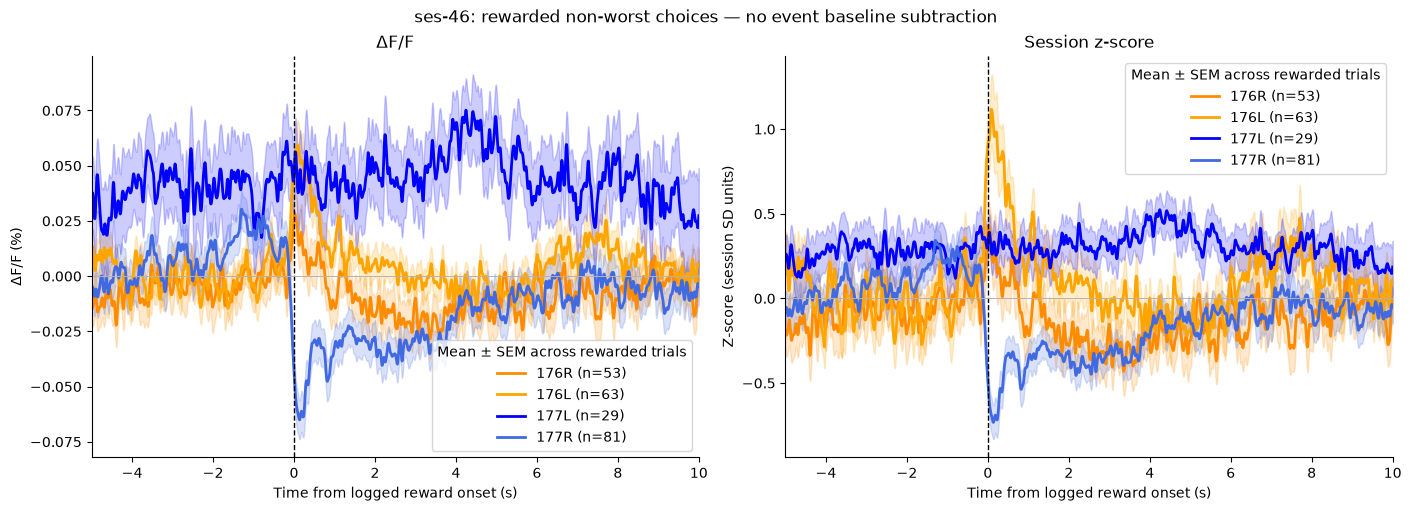

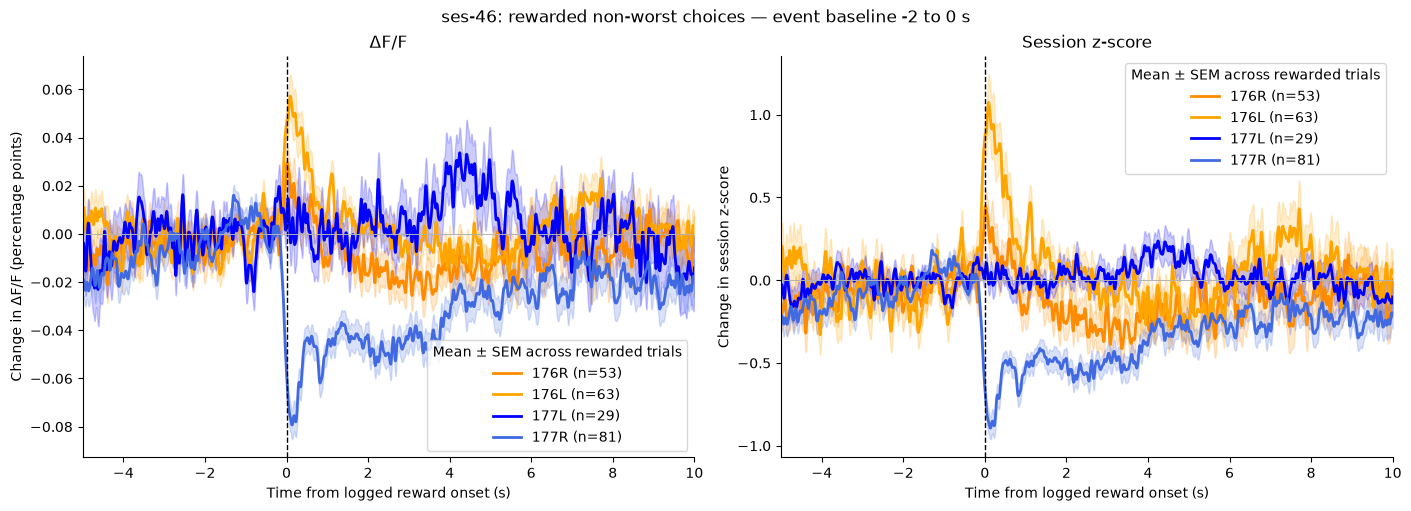

Saved figures, trial audits, and aligned arrays to /Users/megyoung/mini2p-preprocessing/output/photometry_ses34_reward


In [8]:
def plot_reward_comparison(results, subtract_baseline=False):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
    for label, color in [('176R', 'darkorange'), ('176L', 'orange'), ('177L', 'blue'), ('177R', 'royalblue')]:
        result = results[label]
        t = result['relative_time']
        for ax, key in zip(axes, ('dff', 'zscore')):
            trials = result['trials'][key].copy()
            if subtract_baseline:
                if not (t[0] <= BASELINE_S[0] < BASELINE_S[1] <= 0):
                    raise ValueError('Baseline must lie inside the pre-reward window.')
                mask = (t >= BASELINE_S[0]) & (t < BASELINE_S[1])
                if not mask.any(): raise ValueError('Empty event baseline.')
                trials -= trials[:, mask].mean(axis=1, keepdims=True)
            mean = trials.mean(axis=0)
            ax.plot(t, mean, color=color, lw=2, label=f'{label} (n={len(trials)})')
            if len(trials)>1:
                sem = trials.std(axis=0, ddof=1)/np.sqrt(len(trials))
                ax.fill_between(t, mean-sem, mean+sem, color=color, alpha=.2)
    units = ['ΔF/F (%)', 'Z-score (session SD units)']
    if subtract_baseline: units = ['Change in ΔF/F (percentage points)', 'Change in session z-score']
    for ax, title, ylabel in zip(axes, ['ΔF/F', 'Session z-score'], units):
        ax.axvline(0, color='black', ls='--', lw=1)
        ax.axhline(0, color='0.7', lw=.7)
        ax.set(title=title, ylabel=ylabel, xlabel='Time from logged reward onset (s)', xlim=WINDOW_S)
        ax.legend(title='Mean ± SEM across rewarded trials')
    suffix = f'event baseline {BASELINE_S[0]:g} to {BASELINE_S[1]:g} s' if subtract_baseline else 'no event baseline subtraction'
    fig.suptitle(f'ses-{SESSION_NUMBER}: rewarded non-worst choices — {suffix}')
    return fig

if results:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig = plot_reward_comparison(results)
    fig.savefig(OUTPUT_DIR/'reward_aligned_original.png', dpi=180, bbox_inches='tight')
    plt.show()
    if SHOW_BASELINE_SUBTRACTED:
        fig = plot_reward_comparison(results, subtract_baseline=True)
        fig.savefig(OUTPUT_DIR/'reward_aligned_baseline_subtracted.png', dpi=180, bbox_inches='tight')
        plt.show()
    for label, result in results.items():
        result['audit'].to_csv(OUTPUT_DIR/f'{label}_trial_selection.csv', index=False)
        np.savez_compressed(OUTPUT_DIR/f'{label}_reward_aligned.npz',
                            time=result['relative_time'], dff=result['trials']['dff'],
                            zscore=result['trials']['zscore'])
    print('Saved figures, trial audits, and aligned arrays to', OUTPUT_DIR)
else:
    print('No plots generated: awaiting ses-34 data.')


## Supplied-method reward comparison

Matches the **current settings** in the supplied-method cell of `photometry_preprocessing.ipynb`: the same green 10 Hz / order-2 lowpass, double-exponential bleaching correction and control regression used above, followed by trial normalization and an **80-point moving mean**. Reuse the already processed session ΔF/F so the preprocessing is identical.

- Subtract each event's mean ΔF/F over **−5 ≤ time < 0 s** for the ΔF/F panel.
- Calculate trial z-scores from the **unsmoothed ΔF/F**, using that event's **−5 to 0 s** mean and sample SD. These are not the earlier session z-scores.
- Smooth each normalized trial with the centered 80-point moving mean (approximately 0.615 s at 130 Hz), then compute each mouse's mean ± SEM across trials. Centered smoothing can spread a response slightly before event zero.
- Keep rewarded, non-worst choices using the existing audited trial selection. Use the same valid trials for both panels and report additional exclusions. Baselines containing another trial's reward are flagged, but retained to match the previous supplied-method comparison.

These **5-second baselines reflect the edited notebook**, rather than the excerpt's original 20 s / 15 s defaults. The preprocessing and normalization are kept separate, and earlier plots remain unchanged. No equal-mouse curve is added. Peak and signed AUC are descriptive summaries over 0–10 s after the logged reward onset.


176L: 63 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
176R: 53 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
177L: 29 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
177R: 81 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
  Earlier choice reward within baseline for trials: [20, 58]


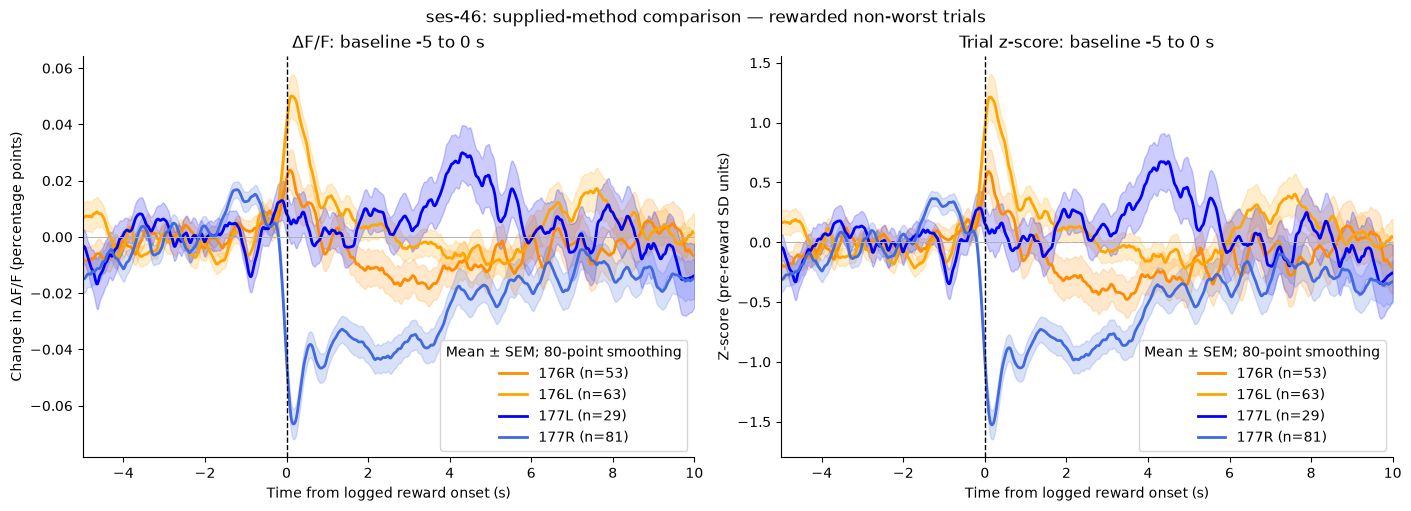

,mouse,n_trials,peak_z,peak_time_s,signed_auc_z_s
0,176L,63,1.214126,0.130769,1.354805
1,176R,53,0.591477,0.084615,-1.339710
2,177L,29,0.674487,4.492308,1.042236
3,177R,81,-0.099784,7.223077,-5.541440


In [19]:
# Same current supplied-method settings as photometry_preprocessing.ipynb.
supplied_dff_baseline = (-5.0, 0.0)
supplied_z_baseline = (-5.0, 0.0)
supplied_smoothing_points = 40
supplied_metric_window = (0.0, 10.0)

def matlab_moving_mean(values, points=80):
    """Centered moving mean on the last axis, matching MATLAB's shrinking endpoints."""
    values = np.asarray(values, dtype=float)
    if points < 1 or int(points) != points:
        raise ValueError('Moving-mean window must be a positive integer.')
    points = int(points)
    indices = np.arange(values.shape[-1])
    starts = np.maximum(0, indices - points // 2)
    stops = np.minimum(values.shape[-1], indices + (points - 1) // 2 + 1)
    sums = np.concatenate([np.zeros(values.shape[:-1] + (1,)),
                           np.cumsum(values, axis=-1)], axis=-1)
    return (sums[..., stops] - sums[..., starts]) / (stops - starts)

supplied_reward_results = {}
if results:
    for label, result in results.items():
        t = result['relative_time']
        trials = result['trials']['dff']  # Unsmoothed, motion-corrected ΔF/F (%).
        masks = []
        for start, end in (supplied_dff_baseline, supplied_z_baseline):
            if not (t[0] <= start < end <= 0):
                raise ValueError('Supplied-method baseline must fit inside the pre-event window.')
            mask = (t >= start) & (t < end)
            if mask.sum() < 2:
                raise ValueError('Baseline needs at least two samples.')
            masks.append(mask)
        dff_mask, z_mask = masks
        baseline_mean = trials[:, z_mask].mean(axis=1, keepdims=True)
        baseline_sd = trials[:, z_mask].std(axis=1, ddof=1, keepdims=True)
        valid = np.isfinite(trials).all(axis=1) & np.isfinite(baseline_sd[:, 0]) & (baseline_sd[:, 0] > 0)
        included_audit = result['audit'].loc[result['audit'].included_in_plot].copy()
        if len(included_audit) != len(trials):
            raise ValueError('Trial audit and event arrays have different lengths.')
        if not valid.any():
            raise ValueError(f'{label}: no trials with a valid baseline SD.')
        selected = trials[valid]
        centered_dff = selected - selected[:, dff_mask].mean(axis=1, keepdims=True)
        trial_z = (selected - baseline_mean[valid]) / baseline_sd[valid]
        np.testing.assert_allclose(centered_dff[:, dff_mask].mean(axis=1), 0, atol=1e-12)
        np.testing.assert_allclose(trial_z[:, z_mask].mean(axis=1), 0, atol=1e-12)
        np.testing.assert_allclose(trial_z[:, z_mask].std(axis=1, ddof=1), 1, atol=1e-12)
        summary = {}
        for key, normalized in [('dff', centered_dff), ('zscore', trial_z)]:
            smoothed = matlab_moving_mean(normalized, supplied_smoothing_points)
            summary[key] = dict(trials=smoothed, trials_unsmoothed=normalized,
                                mean=smoothed.mean(axis=0),
                                sem=smoothed.std(axis=0, ddof=1)/np.sqrt(len(smoothed))
                                    if len(smoothed)>1 else np.full(len(t), np.nan))
        included_audit['included_supplied_method'] = valid
        included_audit['other_reward_in_baseline'] = False
        all_rewards = result['audit'].loc[result['audit'].reward_pulses > 0, 'reward_photometry_s'].to_numpy()
        for row_index, row in included_audit.iterrows():
            onset = row.reward_photometry_s
            included_audit.loc[row_index, 'other_reward_in_baseline'] = bool(np.any(
                (all_rewards >= onset + min(supplied_dff_baseline[0], supplied_z_baseline[0]))
                & (all_rewards < onset)))
        overlap_trials = included_audit.loc[valid & included_audit.other_reward_in_baseline,
                                           'trial'].tolist()
        supplied_reward_results[label] = dict(time=t, summary=summary,
            n_events=int(valid.sum()), audit=included_audit)
        print(f'{label}: {valid.sum()} trials retained; {(~valid).sum()} invalid-baseline exclusions; '
              f'smoothing {supplied_smoothing_points/result["processed"]["fs"]:.3f} s.')
        if overlap_trials:
            print('  Earlier choice reward within baseline for trials:', overlap_trials)
        included_audit.to_csv(OUTPUT_DIR/f'{label}_supplied_method_trial_selection.csv', index=False)
        np.savez_compressed(OUTPUT_DIR/f'{label}_supplied_method_reward_aligned.npz',
                            time=t, dff=summary['dff']['trials'], zscore=summary['zscore']['trials'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
    for label, color in [('176R', 'darkorange'),('176L', 'orange'), ('177L', 'blue'), ('177R', 'royalblue')]:
        result = supplied_reward_results[label]
        for ax, key in zip(axes, ['dff', 'zscore']):
            summary = result['summary'][key]
            ax.plot(result['time'], summary['mean'], color=color, lw=2,
                    label=f"{label} (n={result['n_events']})")
            if result['n_events'] > 1:
                ax.fill_between(result['time'], summary['mean']-summary['sem'],
                                summary['mean']+summary['sem'], color=color, alpha=.2)
    for ax, title, units in zip(
        axes,
        [f'ΔF/F: baseline {supplied_dff_baseline[0]:g} to {supplied_dff_baseline[1]:g} s',
         f'Trial z-score: baseline {supplied_z_baseline[0]:g} to {supplied_z_baseline[1]:g} s'],
        ['Change in ΔF/F (percentage points)', 'Z-score (pre-reward SD units)']
    ):
        ax.axvline(0, color='black', ls='--', lw=1)
        ax.axhline(0, color='0.7', lw=.7)
        ax.set(title=title, ylabel=units, xlabel='Time from logged reward onset (s)', xlim=WINDOW_S)
        ax.legend(title='Mean ± SEM; 80-point smoothing')
    fig.suptitle(f'ses-{SESSION_NUMBER}: supplied-method comparison — rewarded non-worst trials')
    fig.savefig(OUTPUT_DIR/'reward_aligned_supplied_method.png', dpi=180, bbox_inches='tight')
    plt.show()

    from scipy.integrate import trapezoid
    supplied_metrics = []
    for label, result in supplied_reward_results.items():
        t = result['time']
        if not (t[0] <= supplied_metric_window[0] < supplied_metric_window[1] <= t[-1]):
            raise ValueError('Metric window must be covered by extracted trials.')
        mask = (t >= supplied_metric_window[0]) & (t <= supplied_metric_window[1])
        z_mean = result['summary']['zscore']['mean'][mask]
        metric_t = t[mask]
        peak = np.argmax(z_mean)
        supplied_metrics.append(dict(mouse=label, n_trials=result['n_events'],
            peak_z=z_mean[peak], peak_time_s=metric_t[peak], signed_auc_z_s=trapezoid(z_mean, x=metric_t)))
    supplied_metrics = pd.DataFrame(supplied_metrics)
    display(supplied_metrics)
    supplied_metrics.to_csv(OUTPUT_DIR/'supplied_method_peak_auc.csv', index=False)
else:
    print('Supplied-method plots will run after the ses-34 inputs have been processed.')


## Unrewarded trials: supplied-method comparison

Select trials with **zero delivered choice-reward pulses**, including worst/third choices. Unrewarded trials do not enter the `choice` reward-delivery state. Align instead to the **`poked_in` choice-commitment state immediately preceding the printed trial summary**. Require it to be the last preceding state and within 100 ms of that summary; never substitute a hypothetical reward time. These plots therefore use a different logged alignment event from the rewarded plots.

Use the same preprocessing, baseline settings, trial-specific ΔF/F z-scoring and 80-point smoothing as the supplied-method reward plots above. Shade mean ± SEM only for mice with at least two trials. **64N has only one unrewarded trial**, so its curve is a single-trial response with no SEM estimate. The complete trial audit is exported separately. Initiation rewards are not the choice outcomes used to select these trials.


RT_176_L-2026-10-16-153927.tsv: 1 small timestamp inversions (max 1.0 ms), tolerated.
176L: 21 of 21 unrewarded trials have complete windows.
176R: 22 of 23 unrewarded trials have complete windows.
177L: 16 of 16 unrewarded trials have complete windows.
177R: 38 of 38 unrewarded trials have complete windows.
176L: 21 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
176R: 22 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
177L: 16 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
177R: 38 trials retained; 0 invalid-baseline exclusions; smoothing 0.308 s.
  Earlier choice reward within baseline for trials: [6]


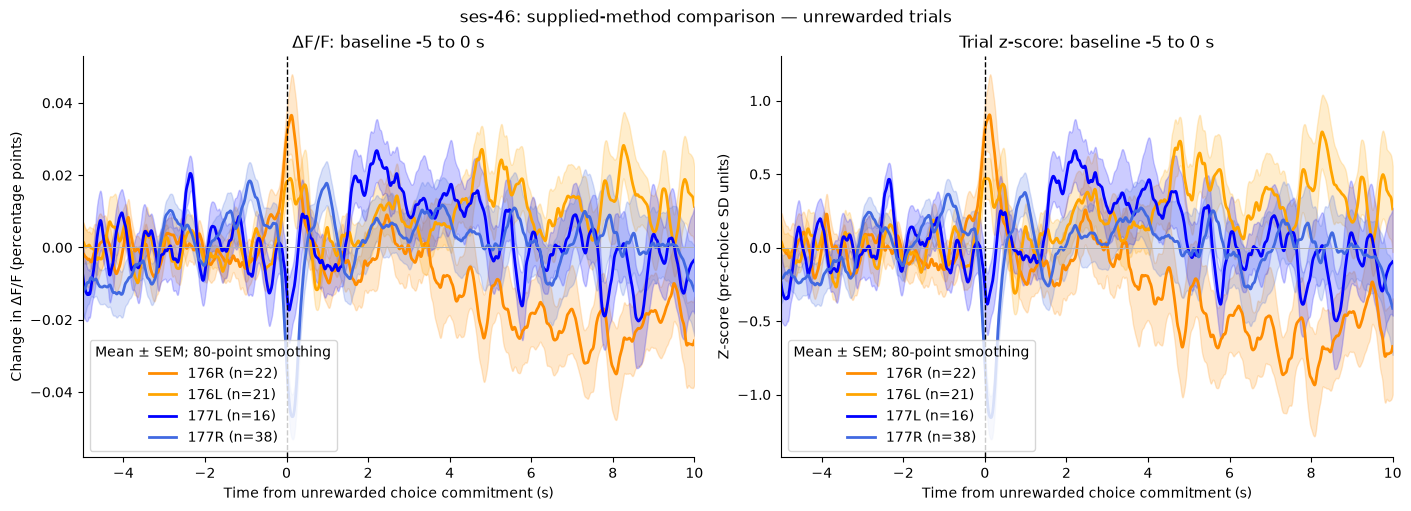

,mouse,n_trials,peak_z,peak_time_s,signed_auc_z_s
0,176L,21,0.787330,8.269231,2.812162
1,176R,22,0.903889,0.115385,-3.173474
2,177L,16,0.660283,2.207692,0.924025
3,177R,38,0.375343,0.984615,-0.074772


In [20]:
# Build separately aligned zero-choice-reward trials without changing rewarded results.
unrewarded_results = {}
if results:
    for label, result in results.items():
        rows = read_behavior(resolved_files[label]['behavior'], SUBJECTS[label])
        audit = result['audit'].copy()
        audit['outcome_behavior_s'] = audit['reward_behavior_s']
        audit['outcome_photometry_s'] = audit['reward_photometry_s']
        audit['selected'] = audit['reward_pulses'].eq(0)
        audit['included_in_plot'] = False
        audit['exclusion_reason'] = np.where(audit['selected'], '', 'rewarded_trial')
        for index, trial in audit.loc[audit.selected].iterrows():
            row_index = int(trial.source_tsv_line) - 2
            previous_state = next((r for r in reversed(rows[:row_index]) if r['type']=='state'), None)
            if previous_state is None or previous_state['content'] != 'poked_in':
                raise ValueError(f'{label} trial {trial.trial}: no immediately preceding poked_in state.')
            onset = float(previous_state['time'])
            if not 0 <= trial.summary_time_s - onset <= 0.1:
                raise ValueError(f'{label} trial {trial.trial}: choice commitment too far from trial summary.')
            audit.loc[index, 'outcome_behavior_s'] = onset
        behavior_sync = result['behavior_sync']
        photo_sync = result['recording'][f'pulse_times_{SYNC_DIGITAL_CHANNEL}']/1000
        audit['outcome_photometry_s'] = np.interp(
            audit['outcome_behavior_s'].to_numpy(), behavior_sync, photo_sync, left=np.nan, right=np.nan)
        selected_indices = np.flatnonzero(audit.selected.to_numpy())
        events = audit.iloc[selected_indices]['outcome_photometry_s'].to_numpy()
        processed = result['processed']
        aligned = {}
        for key in ('dff', 'zscore'):
            t, trials, keep = extract_event_windows(
                processed['time'], processed[key], events, WINDOW_S, processed['fs'],
                (photo_sync[0], photo_sync[-1]))
            aligned[key] = trials
        audit.loc[selected_indices[keep], 'included_in_plot'] = True
        audit.loc[selected_indices[~keep], 'exclusion_reason'] = 'incomplete_window_or_sync_coverage'
        audit.to_csv(OUTPUT_DIR/f'{label}_unrewarded_trial_selection.csv', index=False)
        if not keep.any():
            raise ValueError(f'{label}: no complete unrewarded event windows.')
        unrewarded_results[label] = dict(relative_time=t, trials=aligned, audit=audit, processed=processed)
        print(f'{label}: {keep.sum()} of {len(events)} unrewarded trials have complete windows.')
        if keep.sum() == 1:
            print('  One trial: showing its trace; SEM is undefined and will not be shaded.')

unrewarded_supplied_results = {}
if unrewarded_results:
    for label, result in unrewarded_results.items():
        t = result['relative_time']
        trials = result['trials']['dff']  # Unsmoothed, motion-corrected ΔF/F (%).
        masks = []
        for start, end in (supplied_dff_baseline, supplied_z_baseline):
            if not (t[0] <= start < end <= 0):
                raise ValueError('Supplied-method baseline must fit inside the pre-event window.')
            mask = (t >= start) & (t < end)
            if mask.sum() < 2:
                raise ValueError('Baseline needs at least two samples.')
            masks.append(mask)
        dff_mask, z_mask = masks
        baseline_mean = trials[:, z_mask].mean(axis=1, keepdims=True)
        baseline_sd = trials[:, z_mask].std(axis=1, ddof=1, keepdims=True)
        valid = np.isfinite(trials).all(axis=1) & np.isfinite(baseline_sd[:, 0]) & (baseline_sd[:, 0] > 0)
        included_audit = result['audit'].loc[result['audit'].included_in_plot].copy()
        if len(included_audit) != len(trials):
            raise ValueError('Trial audit and event arrays have different lengths.')
        if not valid.any():
            raise ValueError(f'{label}: no trials with a valid baseline SD.')
        selected = trials[valid]
        centered_dff = selected - selected[:, dff_mask].mean(axis=1, keepdims=True)
        trial_z = (selected - baseline_mean[valid]) / baseline_sd[valid]
        np.testing.assert_allclose(centered_dff[:, dff_mask].mean(axis=1), 0, atol=1e-12)
        np.testing.assert_allclose(trial_z[:, z_mask].mean(axis=1), 0, atol=1e-12)
        np.testing.assert_allclose(trial_z[:, z_mask].std(axis=1, ddof=1), 1, atol=1e-12)
        summary = {}
        for key, normalized in [('dff', centered_dff), ('zscore', trial_z)]:
            smoothed = matlab_moving_mean(normalized, supplied_smoothing_points)
            summary[key] = dict(trials=smoothed, trials_unsmoothed=normalized,
                                mean=smoothed.mean(axis=0),
                                sem=smoothed.std(axis=0, ddof=1)/np.sqrt(len(smoothed))
                                    if len(smoothed)>1 else np.full(len(t), np.nan))
        included_audit['included_supplied_method'] = valid
        included_audit['other_reward_in_baseline'] = False
        all_rewards = result['audit'].loc[result['audit'].reward_pulses > 0, 'outcome_photometry_s'].to_numpy()
        for row_index, row in included_audit.iterrows():
            onset = row.outcome_photometry_s
            included_audit.loc[row_index, 'other_reward_in_baseline'] = bool(np.any(
                (all_rewards >= onset + min(supplied_dff_baseline[0], supplied_z_baseline[0]))
                & (all_rewards < onset)))
        overlap_trials = included_audit.loc[valid & included_audit.other_reward_in_baseline,
                                           'trial'].tolist()
        unrewarded_supplied_results[label] = dict(time=t, summary=summary,
            n_events=int(valid.sum()), audit=included_audit)
        print(f'{label}: {valid.sum()} trials retained; {(~valid).sum()} invalid-baseline exclusions; '
              f'smoothing {supplied_smoothing_points/result["processed"]["fs"]:.3f} s.')
        if overlap_trials:
            print('  Earlier choice reward within baseline for trials:', overlap_trials)
        included_audit.to_csv(OUTPUT_DIR/f'{label}_unrewarded_supplied_method_trial_selection.csv', index=False)
        np.savez_compressed(OUTPUT_DIR/f'{label}_unrewarded_supplied_method_aligned.npz',
                            time=t, dff=summary['dff']['trials'], zscore=summary['zscore']['trials'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, constrained_layout=True)
    for label, color in [('176R', 'darkorange'),('176L', 'orange'), ('177L', 'blue'), ('177R', 'royalblue')]:
        result = unrewarded_supplied_results[label]
        for ax, key in zip(axes, ['dff', 'zscore']):
            summary = result['summary'][key]
            ax.plot(result['time'], summary['mean'], color=color, lw=2,
                    label=f"{label} (n={result['n_events']}" + ('; single trial)' if result['n_events']==1 else ')'))
            if result['n_events'] > 1:
                ax.fill_between(result['time'], summary['mean']-summary['sem'],
                                summary['mean']+summary['sem'], color=color, alpha=.2)
    for ax, title, units in zip(
        axes,
        [f'ΔF/F: baseline {supplied_dff_baseline[0]:g} to {supplied_dff_baseline[1]:g} s',
         f'Trial z-score: baseline {supplied_z_baseline[0]:g} to {supplied_z_baseline[1]:g} s'],
        ['Change in ΔF/F (percentage points)', 'Z-score (pre-choice SD units)']
    ):
        ax.axvline(0, color='black', ls='--', lw=1)
        ax.axhline(0, color='0.7', lw=.7)
        ax.set(title=title, ylabel=units, xlabel='Time from unrewarded choice commitment (s)', xlim=WINDOW_S)
        ax.legend(title='Mean ± SEM; 80-point smoothing')
    fig.suptitle(f'ses-{SESSION_NUMBER}: supplied-method comparison — unrewarded trials')
    fig.savefig(OUTPUT_DIR/'unrewarded_aligned_supplied_method.png', dpi=180, bbox_inches='tight')
    plt.show()

    from scipy.integrate import trapezoid
    unrewarded_supplied_metrics = []
    for label, result in unrewarded_supplied_results.items():
        t = result['time']
        if not (t[0] <= supplied_metric_window[0] < supplied_metric_window[1] <= t[-1]):
            raise ValueError('Metric window must be covered by extracted trials.')
        mask = (t >= supplied_metric_window[0]) & (t <= supplied_metric_window[1])
        z_mean = result['summary']['zscore']['mean'][mask]
        metric_t = t[mask]
        peak = np.argmax(z_mean)
        unrewarded_supplied_metrics.append(dict(mouse=label, n_trials=result['n_events'],
            peak_z=z_mean[peak], peak_time_s=metric_t[peak], signed_auc_z_s=trapezoid(z_mean, x=metric_t)))
    unrewarded_supplied_metrics = pd.DataFrame(unrewarded_supplied_metrics)
    display(unrewarded_supplied_metrics)
    unrewarded_supplied_metrics.to_csv(OUTPUT_DIR/'unrewarded_supplied_method_peak_auc.csv', index=False)
else:
    print('Supplied-method plots will run after the ses-34 inputs have been processed.')


## Within-mouse comparison: rewarded versus unrewarded

Overlay the existing supplied-method responses within each mouse. Rows are mice; columns are baseline-subtracted ΔF/F and trial-specific z-score. Both conditions use the same −5 to 0 s normalization and 80-point smoothing settings above. Shading shows SEM across trials; the single unrewarded 64N trial has no SEM.

**Alignment:** rewarded trials use logged reward-delivery state entry (`choice`), while unrewarded trials use choice commitment (`poked_in`). The shared zero denotes the respective event, not identical physical events. This figure reuses the previously computed arrays without changing their alignment or selection.


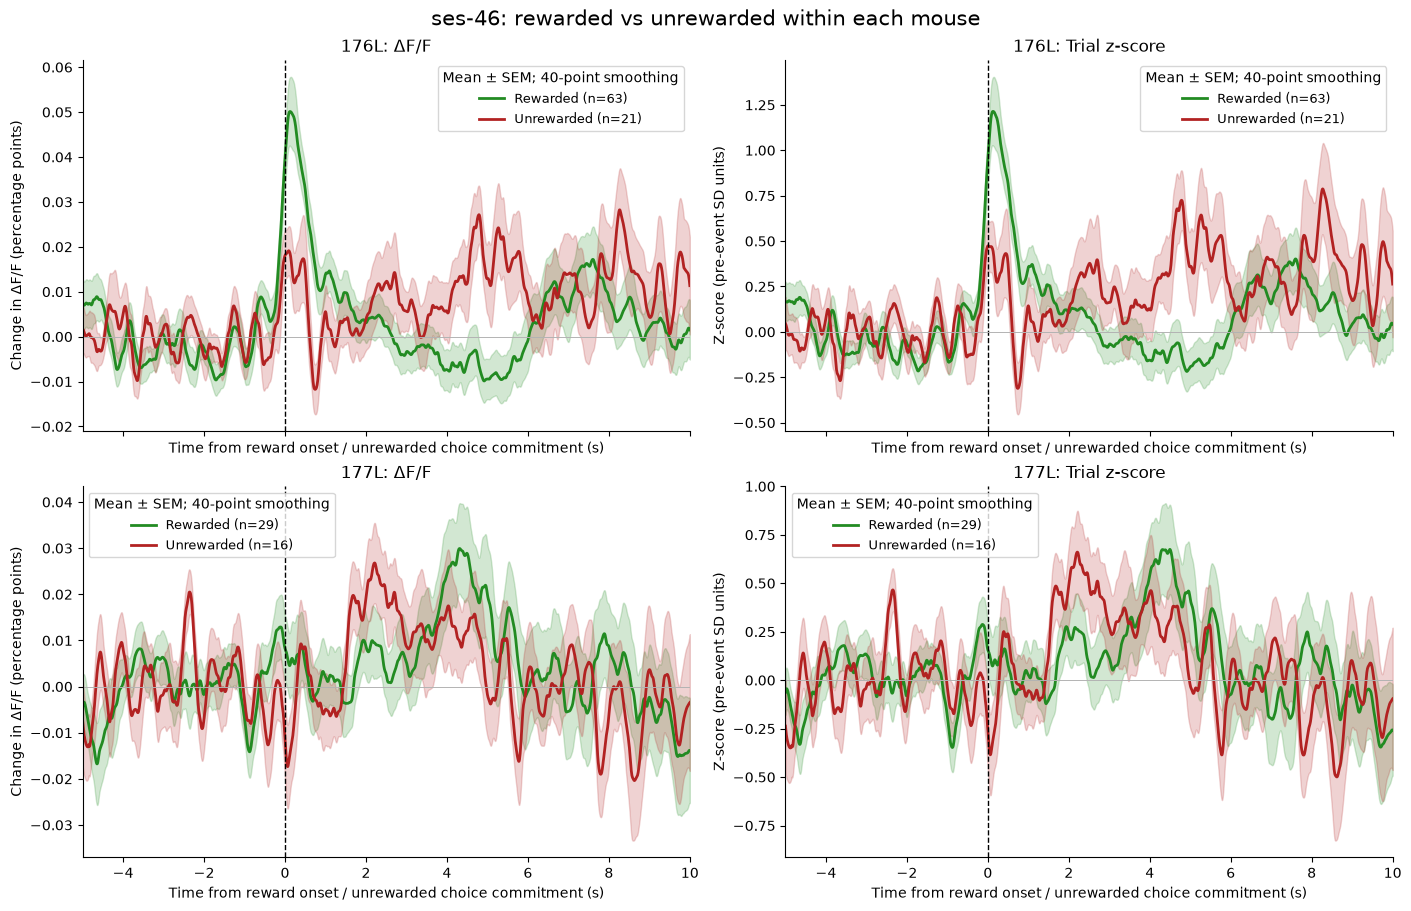

In [23]:
if supplied_reward_results and unrewarded_supplied_results:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, constrained_layout=True)
    for row_index, mouse in enumerate(['176L', '177L']):
        for condition, source, color in [
            ('Rewarded', supplied_reward_results, 'forestgreen'),
            ('Unrewarded', unrewarded_supplied_results, 'firebrick')
        ]:
            result = source[mouse]
            count = result['n_events']
            label = f'{condition} (n={count}' + ('; single trial)' if count == 1 else ')')
            for column_index, key in enumerate(['dff', 'zscore']):
                ax = axes[row_index, column_index]
                summary = result['summary'][key]
                ax.plot(result['time'], summary['mean'], color=color, lw=2, label=label)
                if count > 1:
                    ax.fill_between(result['time'], summary['mean'] - summary['sem'],
                                    summary['mean'] + summary['sem'], color=color, alpha=0.2)
        for column_index, (title, units) in enumerate([
            ('ΔF/F', 'Change in ΔF/F (percentage points)'),
            ('Trial z-score', 'Z-score (pre-event SD units)')
        ]):
            ax = axes[row_index, column_index]
            ax.axvline(0, color='black', ls='--', lw=1)
            ax.axhline(0, color='0.7', lw=0.7)
            ax.set(title=f'{mouse}: {title}', ylabel=units, xlim=WINDOW_S,
                   xlabel='Time from reward onset / unrewarded choice commitment (s)')
            ax.legend(title=f'Mean ± SEM; {supplied_smoothing_points}-point smoothing', fontsize=9)
    fig.suptitle(f'ses-{SESSION_NUMBER}: rewarded vs unrewarded within each mouse', fontsize=15)
    fig.savefig(OUTPUT_DIR / 'within_mouse_rewarded_vs_unrewarded_supplied_method.png',
                dpi=180, bbox_inches='tight')
    plt.show()
else:
    print('Run the rewarded and unrewarded supplied-method sections first.')


## Mean z-score from 0–1 s: trial-level comparisons

For each retained trial, average the **supplied-method smoothed trial z-score** over **0 ≤ time < 1 s**. Bars show the mean of those trial averages; error bars show their SEM (sample SD / √n). Dots show individual trial averages. This is a mean amplitude, not a peak or AUC. SEM is undefined for 64N's single unrewarded trial, so that bar has no error bar.

Panels compare mice within rewarded trials, mice within unrewarded trials, and rewarded versus unrewarded trials within each mouse. As above, time zero is `choice` reward onset for rewarded trials and `poked_in` choice commitment for unrewarded trials. Trials are not paired, and no statistical significance test is applied.


,mouse,condition,n,mean,sem
0,176L,Rewarded,63,0.724333,0.117324
1,176L,Unrewarded,21,0.159273,0.100300
2,176R,Rewarded,53,0.237238,0.146691
3,176R,Unrewarded,22,0.243160,0.156024
4,177L,Rewarded,29,0.064192,0.136390
5,177L,Unrewarded,16,-0.004070,0.157775
6,177R,Rewarded,81,-1.062678,0.098785
7,177R,Unrewarded,38,-0.219795,0.112549


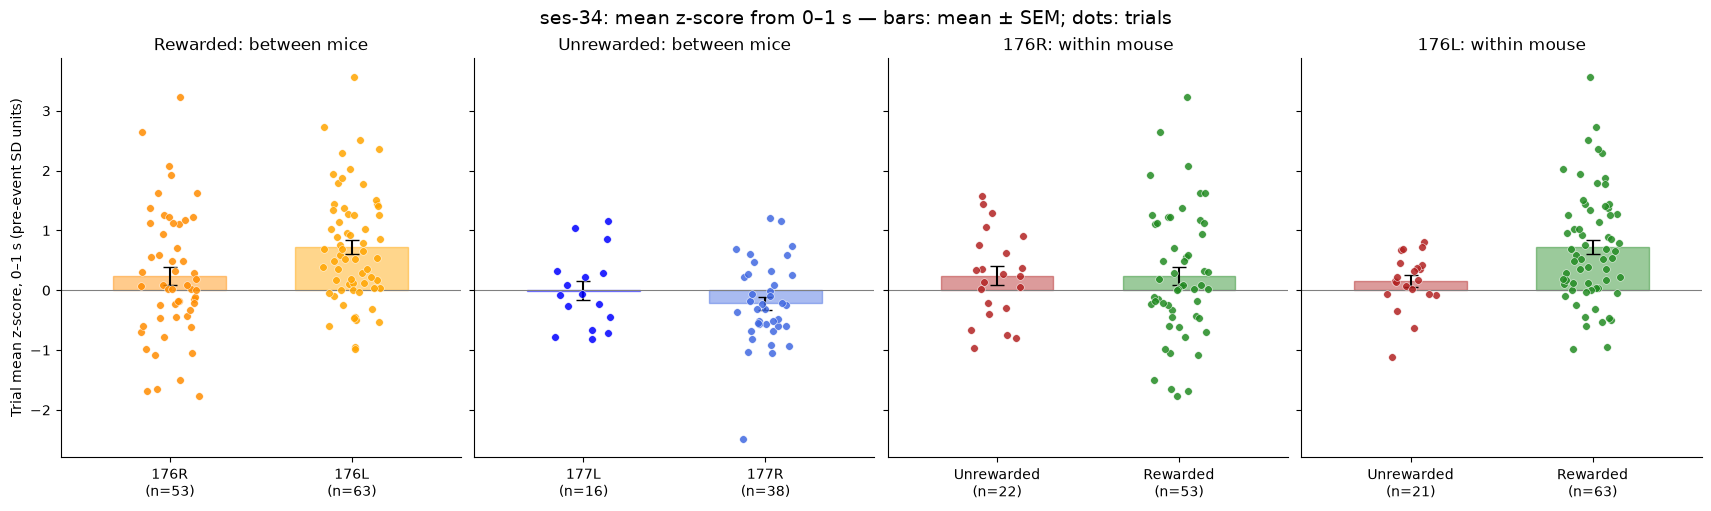

In [17]:
response_bar_window = (0.0, 1.0)  # End excluded.
response_records = []
if supplied_reward_results and unrewarded_supplied_results:
    for condition, source in [('Rewarded', supplied_reward_results),
                              ('Unrewarded', unrewarded_supplied_results)]:
        for mouse in ['176R', '176L', '177L', '177R']:
            result = source[mouse]
            t = result['time']
            mask = (t >= response_bar_window[0]) & (t < response_bar_window[1])
            if not mask.any() or not t[0] <= response_bar_window[0] < response_bar_window[1] <= t[-1]:
                raise ValueError('Response window must be inside the event-aligned time grid.')
            trial_values = result['summary']['zscore']['trials'][:, mask].mean(axis=1)
            audit = result['audit']
            trial_ids = audit.loc[audit.included_supplied_method, 'trial'].to_numpy()
            if len(trial_ids) != len(trial_values):
                raise ValueError('Trial IDs and response amplitudes do not match.')
            for trial, value in zip(trial_ids, trial_values):
                response_records.append(dict(mouse=mouse, condition=condition,
                                             trial=trial, mean_z_0_1s=float(value)))
    response_trial_table = pd.DataFrame(response_records)
    response_bar_summary = (
        response_trial_table.groupby(['mouse', 'condition'])['mean_z_0_1s']
        .agg(n='count', mean='mean', sd='std').reset_index()
    )
    response_bar_summary['sem'] = response_bar_summary['sd'] / np.sqrt(response_bar_summary['n'])
    display(response_bar_summary[['mouse', 'condition', 'n', 'mean', 'sem']])

    fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True, constrained_layout=True)
    panel_specs = [
        ('Rewarded: between mice', [('176R', 'Rewarded'), ('176L', 'Rewarded')],
         ['176R', '176L'], ['darkorange', 'orange']),
        ('Unrewarded: between mice', [('177L', 'Unrewarded'), ('177R', 'Unrewarded')],
         ['177L', '177R'], ['blue', 'royalblue']),
        ('176R: within mouse', [('176R', 'Unrewarded'), ('176R', 'Rewarded')],
         ['Unrewarded', 'Rewarded'], ['firebrick', 'forestgreen']),
        ('176L: within mouse', [('176L', 'Unrewarded'), ('176L', 'Rewarded')],
         ['Unrewarded', 'Rewarded'], ['firebrick', 'forestgreen']),
    ]
    rng = np.random.default_rng(34)  # Reproducible horizontal jitter, for visibility only.
    for ax, (title, groups, tick_labels, colors) in zip(axes, panel_specs):
        labels_with_n = []
        for x, ((mouse, condition), tick_label, color) in enumerate(zip(groups, tick_labels, colors)):
            values = response_trial_table.loc[
                (response_trial_table.mouse == mouse) & (response_trial_table.condition == condition),
                'mean_z_0_1s'].to_numpy()
            mean = values.mean()
            ax.bar(x, mean, width=0.62, color=color, alpha=0.45, edgecolor=color)
            if len(values) > 1:
                sem = values.std(ddof=1) / np.sqrt(len(values))
                ax.errorbar(x, mean, yerr=sem, fmt='none', ecolor='black', capsize=5, lw=1.5)
            ax.scatter(x + rng.uniform(-0.16, 0.16, len(values)), values,
                       color=color, edgecolors='white', linewidths=0.4, s=30, alpha=0.85, zorder=3)
            labels_with_n.append(f'{tick_label}\n(n={len(values)})')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_xticks([0, 1], labels_with_n)
        ax.set(title=title, xlim=(-0.6, 1.6))
    axes[0].set_ylabel('Trial mean z-score, 0–1 s (pre-event SD units)')
    fig.suptitle('ses-34: mean z-score from 0–1 s — bars: mean ± SEM; dots: trials', fontsize=14)
    fig.savefig(OUTPUT_DIR / 'zscore_0_1s_rewarded_unrewarded_bars.png', dpi=180, bbox_inches='tight')
    plt.show()
    response_trial_table.to_csv(OUTPUT_DIR / 'zscore_0_1s_trial_values.csv', index=False)
    response_bar_summary.to_csv(OUTPUT_DIR / 'zscore_0_1s_group_summary.csv', index=False)
else:
    print('Run both supplied-method condition sections first.')


## Original-method 0–1 s bar comparisons

The same four comparisons using **session z-scores of motion-corrected fluorescence** from the original pipeline. Average each trial over **0 ≤ time < 1 s**, then plot group mean ± SEM with individual trials. No event-baseline subtraction, trial-wise re-standardization, or additional 80-point smoothing is applied. The original 10 Hz denoising remains part of preprocessing.

Use the same rewarded/non-worst and zero-reward trial selections and alignments as above. Units are full-session SD units, unlike the supplied-method pre-event SD units. 64N's single unrewarded trial has no SEM estimate. These plots supplement the supplied-method plots rather than replacing them.


In [14]:
original_response_bar_window = (0.0, 1.0)  # End excluded.
original_response_records = []
if results and unrewarded_results:
    for condition, source in [('Rewarded', results),
                              ('Unrewarded', unrewarded_results)]:
        for mouse in ['64N', '65LR']:
            result = source[mouse]
            t = result['relative_time']
            mask = (t >= original_response_bar_window[0]) & (t < original_response_bar_window[1])
            if not mask.any() or not t[0] <= original_response_bar_window[0] < original_response_bar_window[1] <= t[-1]:
                raise ValueError('Response window must be inside the event-aligned time grid.')
            trial_values = result['trials']['zscore'][:, mask].mean(axis=1)
            audit = result['audit']
            trial_ids = audit.loc[audit.included_in_plot, 'trial'].to_numpy()
            if len(trial_ids) != len(trial_values):
                raise ValueError('Trial IDs and response amplitudes do not match.')
            for trial, value in zip(trial_ids, trial_values):
                original_response_records.append(dict(mouse=mouse, condition=condition,
                                             trial=trial, mean_z_0_1s=float(value)))
    original_response_trial_table = pd.DataFrame(original_response_records)
    original_response_bar_summary = (
        original_response_trial_table.groupby(['mouse', 'condition'])['mean_z_0_1s']
        .agg(n='count', mean='mean', sd='std').reset_index()
    )
    original_response_bar_summary['sem'] = original_response_bar_summary['sd'] / np.sqrt(original_response_bar_summary['n'])
    display(original_response_bar_summary[['mouse', 'condition', 'n', 'mean', 'sem']])

    fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True, constrained_layout=True)
    panel_specs = [
        ('Rewarded: between mice', [('64N', 'Rewarded'), ('65LR', 'Rewarded')],
         ['64N', '65LR'], ['darkorange', 'royalblue']),
        ('Unrewarded: between mice', [('64N', 'Unrewarded'), ('65LR', 'Unrewarded')],
         ['64N', '65LR'], ['darkorange', 'royalblue']),
        ('64N: within mouse', [('64N', 'Unrewarded'), ('64N', 'Rewarded')],
         ['Unrewarded', 'Rewarded'], ['firebrick', 'forestgreen']),
        ('65LR: within mouse', [('65LR', 'Unrewarded'), ('65LR', 'Rewarded')],
         ['Unrewarded', 'Rewarded'], ['firebrick', 'forestgreen']),
    ]
    rng = np.random.default_rng(34)  # Reproducible horizontal jitter, for visibility only.
    for ax, (title, groups, tick_labels, colors) in zip(axes, panel_specs):
        labels_with_n = []
        for x, ((mouse, condition), tick_label, color) in enumerate(zip(groups, tick_labels, colors)):
            values = original_response_trial_table.loc[
                (original_response_trial_table.mouse == mouse) & (original_response_trial_table.condition == condition),
                'mean_z_0_1s'].to_numpy()
            mean = values.mean()
            ax.bar(x, mean, width=0.62, color=color, alpha=0.45, edgecolor=color)
            if len(values) > 1:
                sem = values.std(ddof=1) / np.sqrt(len(values))
                ax.errorbar(x, mean, yerr=sem, fmt='none', ecolor='black', capsize=5, lw=1.5)
            ax.scatter(x + rng.uniform(-0.16, 0.16, len(values)), values,
                       color=color, edgecolors='white', linewidths=0.4, s=30, alpha=0.85, zorder=3)
            labels_with_n.append(f'{tick_label}\n(n={len(values)})')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_xticks([0, 1], labels_with_n)
        ax.set(title=title, xlim=(-0.6, 1.6))
    axes[0].set_ylabel('Trial mean z-score, 0–1 s (session SD units)')
    fig.suptitle('ses-34: original-method session z-score, 0–1 s — bars: mean ± SEM; dots: trials', fontsize=14)
    fig.savefig(OUTPUT_DIR / 'original_zscore_0_1s_rewarded_unrewarded_bars.png', dpi=180, bbox_inches='tight')
    plt.show()
    original_response_trial_table.to_csv(OUTPUT_DIR / 'original_zscore_0_1s_trial_values.csv', index=False)
    original_response_bar_summary.to_csv(OUTPUT_DIR / 'original_zscore_0_1s_group_summary.csv', index=False)
else:
    print('Run both rewarded and unrewarded trial extraction sections first.')


KeyError: '64N'

## Post-event peak z-scores: both methods

For each retained trial, take the **maximum signed z-score over 0–10 s**, the full post-event phase. This is a positive-direction peak (not the largest absolute deflection), calculated per trial rather than from the condition-average trace. Bars show the mean of trial peaks ± SEM; dots show individual trial peaks. Peak times and values are exported.

The original method uses session z-scores with no extra moving-mean smoothing; the supplied method uses trial baseline z-scores and the existing 80-point smoothing. Their scales and smoothing differ, so peak amplitudes are not directly interchangeable. Rewarded and unrewarded alignment events remain as documented above. 64N has one unrewarded trial and therefore no SEM. A long post-event window may include later behavior or another trial; peak timing is retained to aid inspection.


In [15]:
peak_post_window = (0.0, 10.0)  # Both endpoints included; edit to change the post phase.
peak_records = []
if results and unrewarded_results and supplied_reward_results and unrewarded_supplied_results:
    for method, condition_sources in [
        ('Original', [('Rewarded', results), ('Unrewarded', unrewarded_results)]),
        ('Supplied', [('Rewarded', supplied_reward_results), ('Unrewarded', unrewarded_supplied_results)])
    ]:
        for condition, source in condition_sources:
            for mouse in ['64N', '65LR']:
                result = source[mouse]
                t = result['relative_time'] if method == 'Original' else result['time']
                trials = (result['trials']['zscore'] if method == 'Original'
                          else result['summary']['zscore']['trials'])
                audit = result['audit']
                keep = audit.included_in_plot if method == 'Original' else audit.included_supplied_method
                trial_ids = audit.loc[keep, 'trial'].to_numpy()
                if len(trial_ids) != len(trials):
                    raise ValueError('Trial IDs and peak inputs do not match.')
                if not t[0] <= peak_post_window[0] < peak_post_window[1] <= t[-1]:
                    raise ValueError('Peak window must be covered by the event-aligned time grid.')
                mask = (t >= peak_post_window[0]) & (t <= peak_post_window[1])
                post = trials[:, mask]
                if not np.isfinite(post).all():
                    raise ValueError('Non-finite samples in the peak window.')
                peak_indices = np.argmax(post, axis=1)
                peak_values = post[np.arange(len(post)), peak_indices]
                peak_times = t[mask][peak_indices]
                for trial, value, peak_time in zip(trial_ids, peak_values, peak_times):
                    peak_records.append(dict(method=method, mouse=mouse, condition=condition,
                                             trial=trial, peak_z=float(value), peak_time_s=float(peak_time)))
    peak_trial_table = pd.DataFrame(peak_records)
    peak_group_summary = (peak_trial_table.groupby(['method', 'mouse', 'condition'])['peak_z']
                          .agg(n='count', mean='mean', sd='std').reset_index())
    peak_group_summary['sem'] = peak_group_summary['sd'] / np.sqrt(peak_group_summary['n'])
    display(peak_group_summary[['method', 'mouse', 'condition', 'n', 'mean', 'sem']])

    for method in ['Original', 'Supplied']:
        fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True, constrained_layout=True)
        rng = np.random.default_rng(34)
        for ax, (title, groups, tick_labels, colors) in zip(axes, panel_specs):
            labels_with_n = []
            for x, ((mouse, condition), tick_label, color) in enumerate(zip(groups, tick_labels, colors)):
                values = peak_trial_table.loc[
                    (peak_trial_table.method == method) & (peak_trial_table.mouse == mouse)
                    & (peak_trial_table.condition == condition), 'peak_z'].to_numpy()
                mean = values.mean()
                ax.bar(x, mean, width=0.62, color=color, alpha=0.45, edgecolor=color)
                if len(values) > 1:
                    sem = values.std(ddof=1) / np.sqrt(len(values))
                    ax.errorbar(x, mean, yerr=sem, fmt='none', ecolor='black', capsize=5, lw=1.5)
                ax.scatter(x + rng.uniform(-0.16, 0.16, len(values)), values, color=color,
                           edgecolors='white', linewidths=0.4, s=30, alpha=0.85, zorder=3)
                labels_with_n.append(f'{tick_label}\n(n={len(values)})')
            ax.axhline(0, color='0.5', lw=0.8)
            ax.set_xticks([0, 1], labels_with_n)
            ax.set(title=title, xlim=(-0.6, 1.6))
        units = 'session SD units' if method == 'Original' else 'pre-event SD units'
        axes[0].set_ylabel(f'Trial peak z-score ({units})')
        fig.suptitle(f'ses-34: {method.lower()} method, peak z-score '
                     f'{peak_post_window[0]:g}–{peak_post_window[1]:g} s — mean ± SEM; dots: trials', fontsize=14)
        fig.savefig(OUTPUT_DIR / f'{method.lower()}_peak_zscore_post_phase_bars.png',
                    dpi=180, bbox_inches='tight')
        plt.show()
    peak_trial_table.to_csv(OUTPUT_DIR / 'peak_zscore_post_phase_trial_values.csv', index=False)
    peak_group_summary.to_csv(OUTPUT_DIR / 'peak_zscore_post_phase_group_summary.csv', index=False)
else:
    print('Run both methods and both conditions first.')


KeyError: '64N'